In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("mall_customers_200.csv")

# Display first five records
print(df.head())

# Dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Select numerical features
X = df[['Annual_Income_k', 'Spending_Score']]


FileNotFoundError: [Errno 2] No such file or directory: 'mall_customers_200.csv'

In [4]:

from google.colab import files
uploaded = files.upload()

import pandas as pd

df = pd.read_csv('mall_customers_200.csv')

print(df.head())
print(df.shape)


Saving mall_customers_200.csv to mall_customers_200.csv
  CustomerID  Annual_Income_k  Spending_Score
0    CUST001               48              51
1    CUST002               29              87
2    CUST003               74              85
3    CUST004               86              18
4    CUST005               24              22
(200, 3)


In [5]:

import pandas as pd

data = {
    'CustomerID': ['CUST001', 'CUST002', 'CUST003', 'CUST004', 'CUST005'],
    'Annual_Income_k': [48, 29, 74, 86, 24],
    'Spending_Score': [51, 87, 85, 18, 22]
}

df = pd.DataFrame(data)

print(df)


  CustomerID  Annual_Income_k  Spending_Score
0    CUST001               48              51
1    CUST002               29              87
2    CUST003               74              85
3    CUST004               86              18
4    CUST005               24              22


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("mall_customers_200.csv")

# Display first five records
print(df.head())

# Dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Select numerical features
X = df[['Annual_Income_k', 'Spending_Score']]


  CustomerID  Annual_Income_k  Spending_Score
0    CUST001               48              51
1    CUST002               29              87
2    CUST003               74              85
3    CUST004               86              18
4    CUST005               24              22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   CustomerID       200 non-null    object
 1   Annual_Income_k  200 non-null    int64 
 2   Spending_Score   200 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 4.8+ KB
None
CustomerID         0
Annual_Income_k    0
Spending_Score     0
dtype: int64


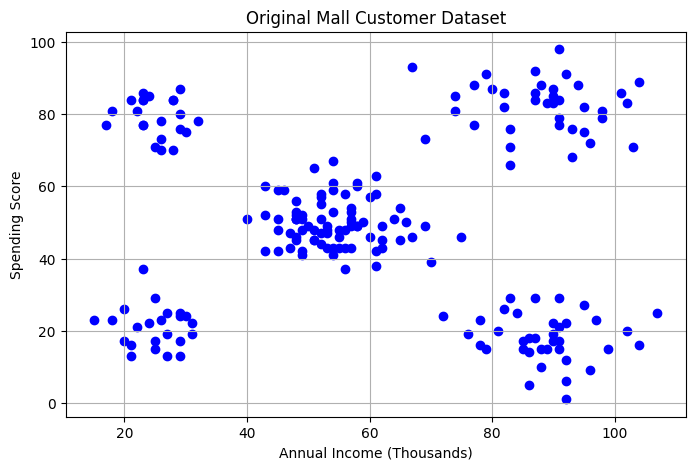

In [8]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income_k'],
    df['Spending_Score'],
    color='blue'
)

plt.xlabel('Annual Income (Thousands)')
plt.ylabel('Spending Score')
plt.title('Original Mall Customer Dataset')

plt.grid(True)
plt.show()


In [9]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [10]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['CustomerID',
          'Annual_Income_k',
          'Spending_Score',
          'Cluster']].to_string(index=False))


CustomerID  Annual_Income_k  Spending_Score  Cluster
   CUST001               48              51        2
   CUST002               29              87        2
   CUST003               74              85        1
   CUST004               86              18        0
   CUST005               24              22        2
   CUST006               62              45        2
   CUST007               81              20        0
   CUST008               51              45        2
   CUST009               21              13        2
   CUST010               61              38        2
   CUST011               95              82        1
   CUST012               55              43        2
   CUST013               58              60        2
   CUST014               93              68        1
   CUST015               91              15        0
   CUST016               91              79        1
   CUST017               65              45        2
   CUST018               92               6   

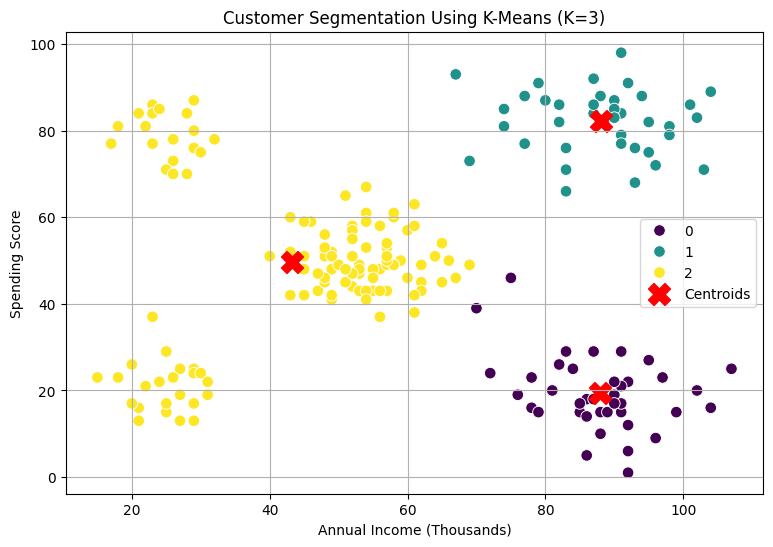

In [11]:

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    color='red',
    label='Centroids'
)

plt.xlabel('Annual Income (Thousands)')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation Using K-Means (K=3)')
plt.legend()
plt.grid(True)
plt.show()


In [12]:

sample = pd.DataFrame({
    'Annual_Income': [1, 1.5, 2, 2, 7, 7.5,
                      8, 8, 4, 4.5, 5, 5],
    'Spending_Score': [1, 2, 1.5, 2.5, 1, 2,
                       1.5, 2.5, 7, 8, 7.5, 8.5]
})

initial_centroids = np.array([
    [1, 1],
    [7, 1],
    [4, 7]
])

km_manual = KMeans(
    n_clusters=3,
    init=initial_centroids,
    n_init=1,
    random_state=42
)

sample['Cluster'] = km_manual.fit_predict(
    sample[['Annual_Income', 'Spending_Score']]
)

print(sample)
print("Final centroids:")
print(km_manual.cluster_centers_)


    Annual_Income  Spending_Score  Cluster
0             1.0             1.0        0
1             1.5             2.0        0
2             2.0             1.5        0
3             2.0             2.5        0
4             7.0             1.0        1
5             7.5             2.0        1
6             8.0             1.5        1
7             8.0             2.5        1
8             4.0             7.0        2
9             4.5             8.0        2
10            5.0             7.5        2
11            5.0             8.5        2
Final centroids:
[[1.625 1.75 ]
 [7.625 1.75 ]
 [4.625 7.75 ]]


In [13]:

wcss = []

for k in range(1, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

# Display WCSS values
wcss_table = pd.DataFrame({
    'Number of Clusters (K)': range(1, 7),
    'WCSS': wcss
})

print(wcss_table)


   Number of Clusters (K)        WCSS
0                       1  400.000000
1                       2  250.464550
2                       3  128.124175
3                       4   75.300586
4                       5   28.336033
5                       6   24.355411


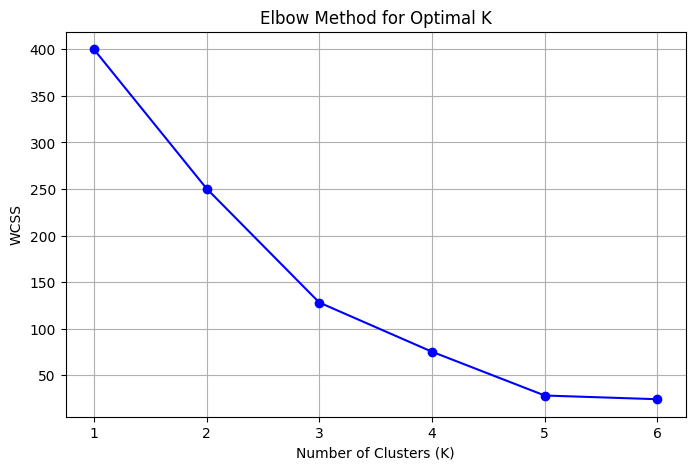

In [14]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    color='blue'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')

plt.xticks(range(1, 7))
plt.grid(True)

plt.show()


In [15]:

# Enter the K selected from the Elbow Graph
optimal_k = 5  # Change this if your graph indicates another K

final_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Final_Cluster'] = final_model.fit_predict(X_scaled)

final_centroids = scaler.inverse_transform(
    final_model.cluster_centers_
)

print("Final cluster counts:")
print(df['Final_Cluster'].value_counts().sort_index())

print("\nFinal Centroids:")
print(final_centroids)


Final cluster counts:
Final_Cluster
0    37
1    38
2    80
3    22
4    23
Name: count, dtype: int64

Final Centroids:
[[88.7027027  18.08108108]
 [88.05263158 82.18421053]
 [54.1625     49.7625    ]
 [25.13636364 79.18181818]
 [24.95652174 21.        ]]


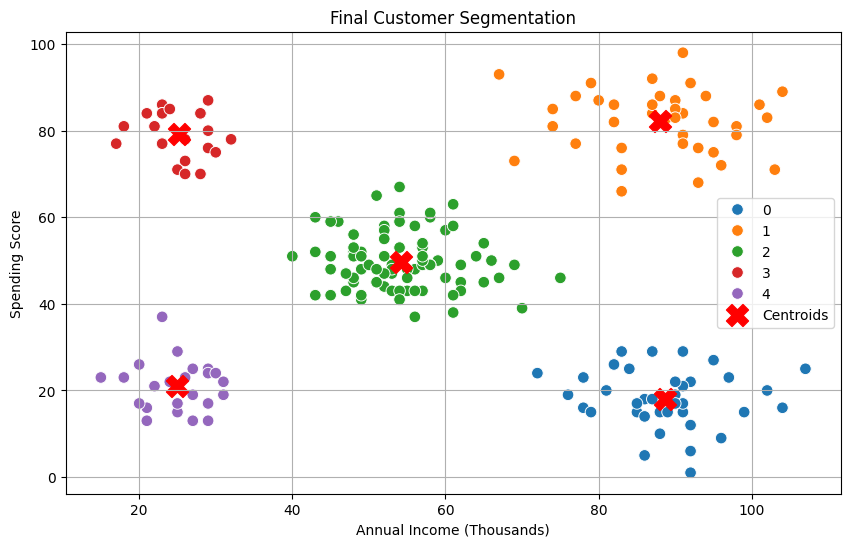

In [16]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Final_Cluster',
    palette='tab10',
    s=70
)

plt.scatter(
    final_centroids[:, 0],
    final_centroids[:, 1],
    marker='X',
    color='red',
    s=250,
    label='Centroids'
)

plt.xlabel('Annual Income (Thousands)')
plt.ylabel('Spending Score')
plt.title('Final Customer Segmentation')

plt.legend()
plt.grid(True)
plt.show()
